In [2]:
# SECTION 1: IMPORTING ALL REQUIRED LIBRARIES
# These libraries are used for data processing, machine learning,
# deep learning, visualization, and model evaluation.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings

warnings.filterwarnings('ignore')

# Machine Learning Libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_auc_score, roc_curve
)
from sklearn.utils.class_weight import compute_class_weight

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

# Deep Learning Libraries
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense, Dropout, Conv1D, MaxPooling1D,
    Flatten, LSTM, GRU
)
from tensorflow.keras.callbacks import EarlyStopping

# Display TensorFlow Version
print("TensorFlow Version:", tf.__version__)
print("All Libraries Imported Successfully!")

TensorFlow Version: 2.21.0
All Libraries Imported Successfully!


In [3]:
# SECTION 2: CONNECTING GOOGLE DRIVE
# Mount Google Drive to access the diabetes dataset.

from google.colab import drive

drive.mount('/content/drive', force_remount=True)

print("Google Drive Connected Successfully!")

Mounted at /content/drive
Google Drive Connected Successfully!


In [4]:
# SECTION 3: LOADING THE DIABETES DATASET
# Reading the CSV file directly from the Google Drive folder.

file_path = '/content/drive/MyDrive/MCA3/DSP_Project/Diabetes_Prediction_dataset/diabetes_prediction_dataset.csv'

df = pd.read_csv(file_path)

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

# Display first five records
display(df.head())

Dataset Loaded Successfully!
Dataset Shape: (100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [5]:
# SECTION 4: EXPLORATORY DATA ANALYSIS (EDA)
# Understanding dataset structure, data types, missing values,
# statistical information, and duplicate records.

# Display dataset information
print("Dataset Information:")
df.info()

# Display statistical summary
print("\nStatistical Summary:")
display(df.describe(include='all'))

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Display column names
print("\nDataset Columns:")
print(df.columns.tolist())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB

Statistical Summary:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000,100000.000000,100000.00000,100000.000000,100000,100000.000000,100000.000000,100000.000000,100000.000000
unique,3,NaN,NaN,NaN,6,NaN,NaN,NaN,NaN
top,Female,NaN,NaN,NaN,No Info,NaN,NaN,NaN,NaN
freq,58552,NaN,NaN,NaN,35816,NaN,NaN,NaN,NaN
mean,NaN,41.885856,0.07485,0.039420,NaN,27.320767,5.527507,138.058060,0.085000
std,NaN,22.516840,0.26315,0.194593,NaN,6.636783,1.070672,40.708136,0.278883
min,NaN,0.080000,0.00000,0.000000,NaN,10.010000,3.500000,80.000000,0.000000
25%,NaN,24.000000,0.00000,0.000000,NaN,23.630000,4.800000,100.000000,0.000000
50%,NaN,43.000000,0.00000,0.000000,NaN,27.320000,5.800000,140.000000,0.000000
75%,NaN,60.000000,0.00000,0.000000,NaN,29.580000,6.200000,159.000000,0.000000



Missing Values:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

Duplicate Records: 3854

Dataset Columns:
['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']


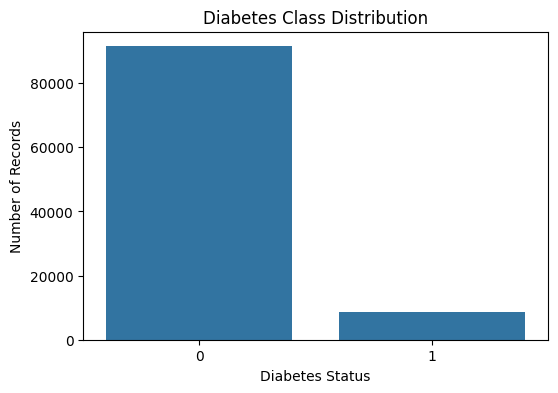

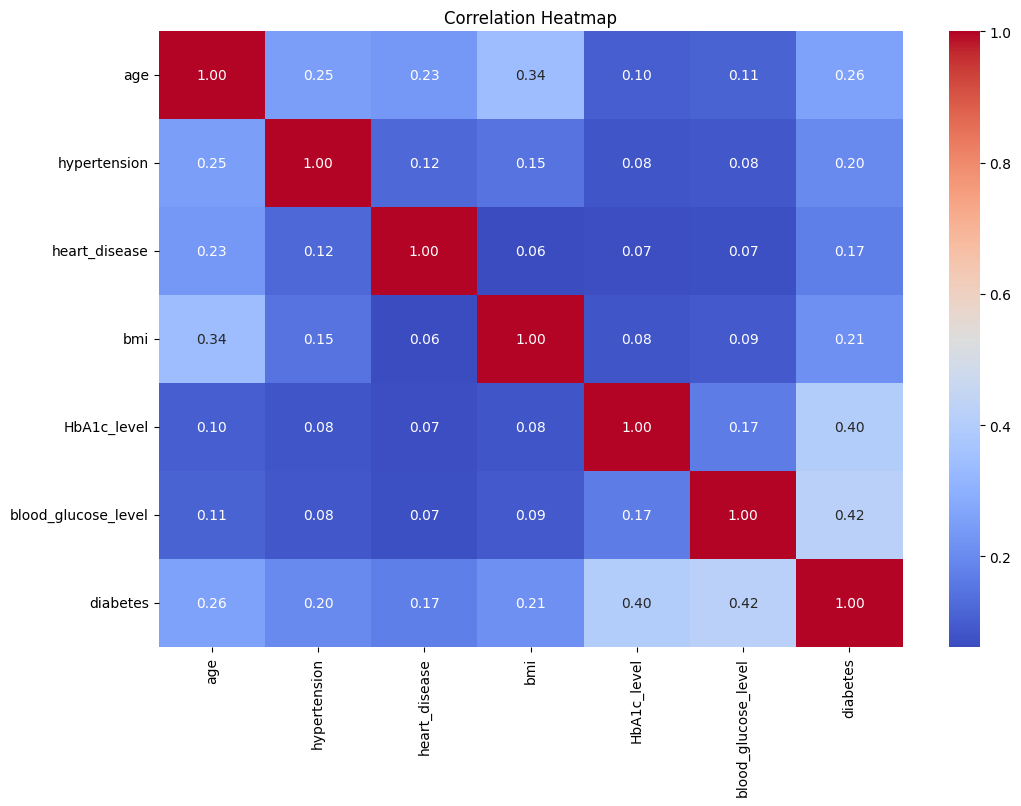

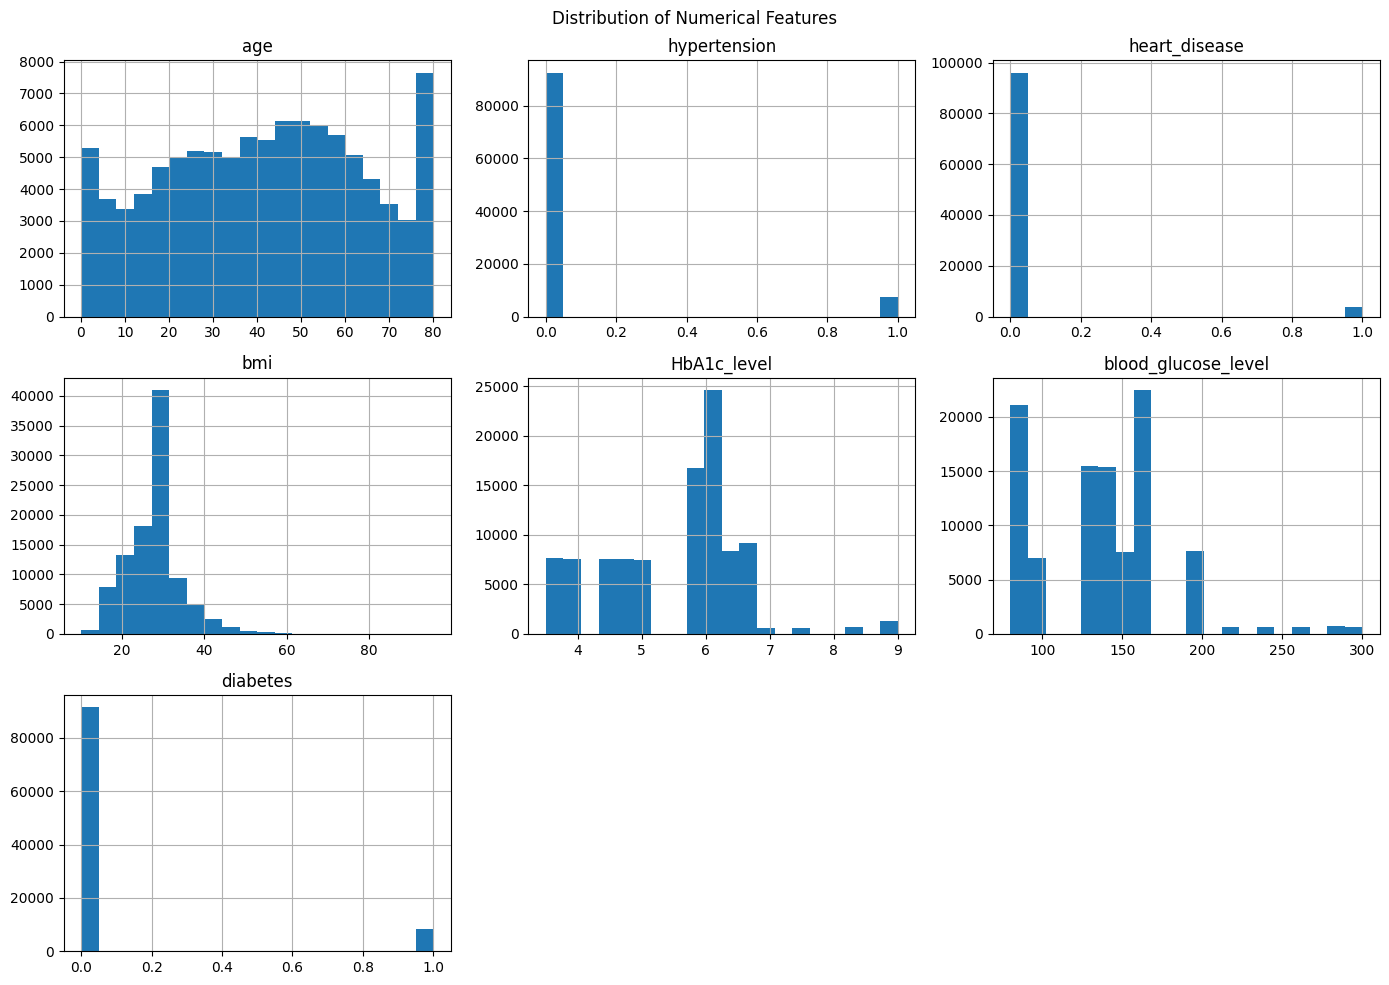

In [6]:
# SECTION 5: DATA VISUALIZATION
# Visualizing the dataset to understand feature distributions
# and the distribution of diabetes and non-diabetes cases.

# Display target distribution if the target column is named diabetes
if 'diabetes' in df.columns:
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x='diabetes')
    plt.title("Diabetes Class Distribution")
    plt.xlabel("Diabetes Status")
    plt.ylabel("Number of Records")
    plt.show()

# Display correlation heatmap for numerical columns
plt.figure(figsize=(12, 8))

numeric_df = df.select_dtypes(include=np.number)

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

# Display numerical feature distributions
numeric_df.hist(figsize=(14, 10), bins=20)
plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

In [7]:
# SECTION 6: DATA PREPROCESSING
# Identifying the target variable, handling missing values,
# encoding categorical features, and preparing input features.

# Automatically identify the target column
possible_targets = [
    'diabetes', 'Diabetes', 'Outcome',
    'outcome', 'target', 'Target', 'class'
]

target_column = next(
    (col for col in possible_targets if col in df.columns),
    None
)

if target_column is None:
    raise ValueError(
        "Target column not found. Please check your dataset columns."
    )

print("Target Column:", target_column)

# Remove duplicate records
df = df.drop_duplicates()

# Remove records with missing target values
df = df.dropna(subset=[target_column])

# Separate input features and target variable
X = df.drop(columns=[target_column])
y = df[target_column]

# Remove identifier columns if present
id_columns = [
    col for col in X.columns
    if col.lower() in ['id', 'patient_id', 'patientid']
]

X = X.drop(columns=id_columns)

# Convert target labels into numeric values if necessary
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y.astype(str))

# Check target classes
print("\nTarget Classes:", label_encoder.classes_)
print("Number of Classes:", len(np.unique(y)))

# This implementation is designed for binary diabetes classification
if len(np.unique(y)) != 2:
    raise ValueError("This notebook currently supports binary classification only.")

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("\nNumerical Features:", numeric_features)
print("Categorical Features:", categorical_features)

# Create preprocessing pipelines
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

# Apply transformations to the appropriate columns
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='drop'
)

print("\nPreprocessing Configuration Created Successfully!")

Target Column: diabetes

Target Classes: ['0' '1']
Number of Classes: 2

Numerical Features: ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level']
Categorical Features: ['gender', 'smoking_history']

Preprocessing Configuration Created Successfully!


In [8]:
# SECTION 7: TRAIN-TEST SPLITTING
# Splitting the dataset into 80% training data and 20% testing data.
# Stratification maintains the class distribution in both sets.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Fit preprocessing only on training data to prevent data leakage
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

# Convert processed data into NumPy arrays
X_train = np.asarray(X_train, dtype=np.float32)
X_test = np.asarray(X_test, dtype=np.float32)

y_train = np.asarray(y_train, dtype=np.int32)
y_test = np.asarray(y_test, dtype=np.int32)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nData Splitting Completed Successfully!")

Training Data Shape: (76916, 15)
Testing Data Shape: (19230, 15)

Data Splitting Completed Successfully!


In [9]:
# SECTION 8: MODEL EVALUATION FUNCTION
# This function calculates accuracy, precision, recall,
# F1-score, ROC-AUC, and training time for each model.

results = []
model_predictions = {}
model_probabilities = {}
trained_models = {}

def evaluate_model(name, y_true, y_pred, y_prob, training_time):

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auc = roc_auc_score(y_true, y_prob)

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'ROC-AUC': auc,
        'Training Time (sec)': training_time
    })

    model_predictions[name] = y_pred
    model_probabilities[name] = y_prob

    print(f"\n{name} Results")
    print("-" * 40)
    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))
    print("ROC-AUC  :", round(auc, 4))
    print("Training Time:", round(training_time, 2), "seconds")

    print("\nClassification Report:")
    print(classification_report(
        y_true, y_pred,
        target_names=['No Diabetes', 'Diabetes'],
        zero_division=0
    ))

In [10]:
# SECTION 9: MACHINE LEARNING MODEL 1 - LOGISTIC REGRESSION
# Logistic Regression predicts the probability of a binary outcome,
# such as whether a person has diabetes or does not have diabetes.

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

start_time = time.time()

lr_model.fit(X_train, y_train)

training_time = time.time() - start_time

y_pred = lr_model.predict(X_test)
y_prob = lr_model.predict_proba(X_test)[:, 1]

trained_models['Logistic Regression'] = lr_model

evaluate_model(
    'Logistic Regression',
    y_test, y_pred, y_prob, training_time
)


Logistic Regression Results
----------------------------------------
Accuracy : 0.9596
Precision: 0.8692
Recall   : 0.6386
F1 Score : 0.7362
ROC-AUC  : 0.9599
Training Time: 0.21 seconds

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.97      0.99      0.98     17534
    Diabetes       0.87      0.64      0.74      1696

    accuracy                           0.96     19230
   macro avg       0.92      0.81      0.86     19230
weighted avg       0.96      0.96      0.96     19230



In [11]:
# SECTION 10: MACHINE LEARNING MODEL 2 - DECISION TREE
# Decision Tree uses a tree-like structure of decision rules
# to classify patients based on their health-related features.

dt_model = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)

start_time = time.time()

dt_model.fit(X_train, y_train)

training_time = time.time() - start_time

y_pred = dt_model.predict(X_test)
y_prob = dt_model.predict_proba(X_test)[:, 1]

trained_models['Decision Tree'] = dt_model

evaluate_model(
    'Decision Tree',
    y_test, y_pred, y_prob, training_time
)


Decision Tree Results
----------------------------------------
Accuracy : 0.9709
Precision: 0.9734
Recall   : 0.6893
F1 Score : 0.807
ROC-AUC  : 0.9724
Training Time: 0.17 seconds

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.97      1.00      0.98     17534
    Diabetes       0.97      0.69      0.81      1696

    accuracy                           0.97     19230
   macro avg       0.97      0.84      0.90     19230
weighted avg       0.97      0.97      0.97     19230



In [15]:
# SECTION 11: MACHINE LEARNING MODEL 3 - RANDOM FOREST
# Random Forest combines multiple decision trees to improve
# prediction stability and reduce overfitting.

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

rf_model.fit(X_train, y_train)

training_time = time.time() - start_time

y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

trained_models['Random Forest'] = rf_model

evaluate_model(
    'Random Forest',
    y_test, y_pred, y_prob, training_time
)


Random Forest Results
----------------------------------------
Accuracy : 0.9715
Precision: 0.9906
Recall   : 0.6828
F1 Score : 0.8084
ROC-AUC  : 0.9706
Training Time: 3.39 seconds

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.97      1.00      0.98     17534
    Diabetes       0.99      0.68      0.81      1696

    accuracy                           0.97     19230
   macro avg       0.98      0.84      0.90     19230
weighted avg       0.97      0.97      0.97     19230



In [16]:
# SECTION 12: MACHINE LEARNING MODEL 4 - SUPPORT VECTOR MACHINE
# SVM finds an optimal decision boundary that separates
# diabetes and non-diabetes classes.

svm_model = SVC(
    kernel='rbf',
    probability=True,
    random_state=42
)

start_time = time.time()

svm_model.fit(X_train, y_train)

training_time = time.time() - start_time

y_pred = svm_model.predict(X_test)
y_prob = svm_model.predict_proba(X_test)[:, 1]

trained_models['SVM'] = svm_model

evaluate_model(
    'SVM',
    y_test, y_pred, y_prob, training_time
)


SVM Results
----------------------------------------
Accuracy : 0.9626
Precision: 0.9701
Recall   : 0.5938
F1 Score : 0.7366
ROC-AUC  : 0.9296
Training Time: 243.23 seconds

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.96      1.00      0.98     17534
    Diabetes       0.97      0.59      0.74      1696

    accuracy                           0.96     19230
   macro avg       0.97      0.80      0.86     19230
weighted avg       0.96      0.96      0.96     19230



In [17]:
# SECTION 13: MACHINE LEARNING MODEL 5 - K-NEAREST NEIGHBORS
# KNN classifies a patient based on the majority class
# among the nearest neighboring data points.

knn_model = KNeighborsClassifier(
    n_neighbors=5,
    n_jobs=-1
)

start_time = time.time()

knn_model.fit(X_train, y_train)

training_time = time.time() - start_time

y_pred = knn_model.predict(X_test)
y_prob = knn_model.predict_proba(X_test)[:, 1]

trained_models['KNN'] = knn_model

evaluate_model(
    'KNN',
    y_test, y_pred, y_prob, training_time
)


KNN Results
----------------------------------------
Accuracy : 0.9593
Precision: 0.8853
Recall   : 0.6191
F1 Score : 0.7287
ROC-AUC  : 0.9008
Training Time: 0.29 seconds

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.96      0.99      0.98     17534
    Diabetes       0.89      0.62      0.73      1696

    accuracy                           0.96     19230
   macro avg       0.92      0.81      0.85     19230
weighted avg       0.96      0.96      0.96     19230



In [18]:
# SECTION 1: SAVING MACHINE LEARNING MODEL RESULTS
# This section saves the performance metrics of all five
# Machine Learning algorithms into Google Drive.

import os
import pandas as pd
import numpy as np

# Create a folder in Google Drive
output_folder = '/content/drive/MyDrive/MCA3/DSP_Project/results'

os.makedirs(output_folder, exist_ok=True)

# List of five Machine Learning models
ml_models = [
    'Logistic Regression',
    'Decision Tree',
    'Random Forest',
    'SVM',
    'KNN'
]

# Filter only Machine Learning results
ml_results = [
    result for result in results
    if result['Model'] in ml_models
]

# Convert results into DataFrame
ml_results_df = pd.DataFrame(ml_results)

# Sort according to accuracy
ml_results_df = ml_results_df.sort_values(
    by='Accuracy',
    ascending=False
)

# Save performance metrics as CSV
ml_results_df.to_csv(
    output_folder + '/ML_Performance_Metrics.csv',
    index=False
)

print("Machine Learning Performance Metrics Saved!")
display(ml_results_df)

Machine Learning Performance Metrics Saved!


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (sec)
3,Random Forest,0.971451,0.990590,0.682783,0.808377,0.970574,3.392694
2,Random Forest,0.971451,0.990590,0.682783,0.808377,0.970574,7.303424
1,Decision Tree,0.970931,0.973356,0.689269,0.807042,0.972448,0.173980
4,SVM,0.962559,0.970135,0.593750,0.736650,0.929631,243.230000
0,Logistic Regression,0.959646,0.869181,0.638561,0.736234,0.959896,0.205132
5,KNN,0.959334,0.885329,0.619104,0.728661,0.900810,0.287795


In [19]:
# ============================================================
# SECTION: SAVING ALL MACHINE LEARNING RESULTS
# Destination: My Drive/3 rd sem Practical/Result
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# 1. Set Result Folder Path
output_folder = '/content/drive/MyDrive/MCA3/DSP_Project/results'
os.makedirs(output_folder, exist_ok=True)

# 2. Define Machine Learning Models
ml_models = [
    'Logistic Regression',
    'Decision Tree',
    'Random Forest',
    'SVM',
    'KNN'
]

# 3. Save Performance Metrics
ml_results = [
    r for r in results
    if r['Model'] in ml_models
]

ml_results_df = pd.DataFrame(ml_results)

ml_results_df = ml_results_df.sort_values(
    by='Accuracy',
    ascending=False
)

ml_results_df.to_csv(
    output_folder + '/ML_Performance_Metrics.csv',
    index=False
)

# 4. Save Individual Confusion Matrices
for model_name in ml_models:

    cm = confusion_matrix(
        y_test,
        model_predictions[model_name]
    )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['No Diabetes', 'Diabetes'],
        yticklabels=['No Diabetes', 'Diabetes']
    )

    plt.title(model_name + ' Confusion Matrix')
    plt.xlabel('Predicted Label')
    plt.ylabel('Actual Label')

    file_name = model_name.replace(' ', '_')

    plt.savefig(
        output_folder + '/' + file_name + '_Confusion_Matrix.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.close()

# 5. Save Combined Accuracy Comparison Graph
plt.figure(figsize=(12, 6))

sns.barplot(
    data=ml_results_df,
    x='Model',
    y='Accuracy'
)

plt.title('Accuracy Comparison - Machine Learning Models')
plt.xlabel('Algorithms')
plt.ylabel('Accuracy')
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    output_folder + '/ML_Accuracy_Comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.close()

# 6. Save Classification Reports
with open(
    output_folder + '/ML_Classification_Reports.txt',
    'w'
) as file:

    for model_name in ml_models:

        report = classification_report(
            y_test,
            model_predictions[model_name],
            target_names=['No Diabetes', 'Diabetes'],
            zero_division=0
        )

        file.write('\n' + '=' * 60 + '\n')
        file.write(model_name + '\n')
        file.write('=' * 60 + '\n')
        file.write(report + '\n')

# 7. Save Actual vs Predicted Results
prediction_df = pd.DataFrame({
    'Actual': y_test
})

for model_name in ml_models:
    prediction_df[model_name] = model_predictions[model_name]

prediction_df.to_csv(
    output_folder + '/ML_Actual_vs_Predicted.csv',
    index=False
)

# 8. Save Complete Results in Excel
excel_path = output_folder + '/Complete_ML_Results.xlsx'

with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:

    ml_results_df.to_excel(
        writer,
        sheet_name='Performance Metrics',
        index=False
    )

    prediction_df.to_excel(
        writer,
        sheet_name='Predictions',
        index=False
    )

    for model_name in ml_models:

        cm = confusion_matrix(
            y_test,
            model_predictions[model_name]
        )

        cm_df = pd.DataFrame(
            cm,
            index=['Actual No Diabetes', 'Actual Diabetes'],
            columns=['Predicted No Diabetes', 'Predicted Diabetes']
        )

        cm_df.to_excel(
            writer,
            sheet_name=model_name[:25]
        )

# 9. Display Final Results
print("\n" + "=" * 60)
print("ALL MACHINE LEARNING RESULTS SAVED SUCCESSFULLY!")
print("=" * 60)

print("\nBest Performing ML Model:")
print(ml_results_df.iloc[0]['Model'])

print(
    "Best Accuracy:",
    round(ml_results_df.iloc[0]['Accuracy'] * 100, 2),
    "%"
)

print("\nSaved Location:")
print(output_folder)

print("\nFiles Saved:")
for filename in sorted(os.listdir(output_folder)):
    print("✔", filename)

print("\n" + "=" * 60)
display(ml_results_df)


ALL MACHINE LEARNING RESULTS SAVED SUCCESSFULLY!

Best Performing ML Model:
Random Forest
Best Accuracy: 97.15 %

Saved Location:
/content/drive/MyDrive/MCA3/DSP_Project/results

Files Saved:
✔ Complete_ML_Results.xlsx
✔ DL results
✔ Decision_Tree_Confusion_Matrix.png
✔ KNN_Confusion_Matrix.png
✔ Logistic_Regression_Confusion_Matrix.png
✔ ML_Accuracy_Comparison.png
✔ ML_Actual_vs_Predicted.csv
✔ ML_Classification_Reports.txt
✔ ML_Performance_Metrics.csv
✔ Random_Forest_Confusion_Matrix.png
✔ SVM_Confusion_Matrix.png



,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (sec)
3,Random Forest,0.971451,0.990590,0.682783,0.808377,0.970574,3.392694
2,Random Forest,0.971451,0.990590,0.682783,0.808377,0.970574,7.303424
1,Decision Tree,0.970931,0.973356,0.689269,0.807042,0.972448,0.173980
4,SVM,0.962559,0.970135,0.593750,0.736650,0.929631,243.230000
0,Logistic Regression,0.959646,0.869181,0.638561,0.736234,0.959896,0.205132
5,KNN,0.959334,0.885329,0.619104,0.728661,0.900810,0.287795


In [20]:
# SECTION 1: IMPORTING ALL REQUIRED LIBRARIES
# These libraries are used for data processing, machine learning,
# deep learning, visualization, and model evaluation.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings

warnings.filterwarnings('ignore')

# Machine Learning Libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_auc_score, roc_curve
)
from sklearn.utils.class_weight import compute_class_weight

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

# Deep Learning Libraries
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense, Dropout, Conv1D, MaxPooling1D,
    Flatten, LSTM, GRU
)
from tensorflow.keras.callbacks import EarlyStopping

# Display TensorFlow Version
print("TensorFlow Version:", tf.__version__)
print("All Libraries Imported Successfully!")

TensorFlow Version: 2.21.0
All Libraries Imported Successfully!


In [21]:
# SECTION 2: CONNECTING GOOGLE DRIVE
# This allows Google Colab to access the dataset stored in Drive.

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive Connected Successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive Connected Successfully!


In [22]:
# SECTION 3: LOADING THE DIABETES DATASET
# Reading the CSV file directly from the Google Drive folder.

file_path = '/content/drive/MyDrive/MCA3/DSP_Project/Diabetes_Prediction_dataset/diabetes_prediction_dataset.csv'

df = pd.read_csv(file_path)

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

# Display first five records
display(df.head())

Dataset Loaded Successfully!
Dataset Shape: (100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [23]:
# SECTION 4: EXPLORATORY DATA ANALYSIS (EDA)
# Understanding dataset structure, data types, missing values,
# statistical information, and duplicate records.

# Display dataset information
print("Dataset Information:")
df.info()

# Display statistical summary
print("\nStatistical Summary:")
display(df.describe(include='all'))

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Display column names
print("\nDataset Columns:")
print(df.columns.tolist())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB

Statistical Summary:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000,100000.000000,100000.00000,100000.000000,100000,100000.000000,100000.000000,100000.000000,100000.000000
unique,3,NaN,NaN,NaN,6,NaN,NaN,NaN,NaN
top,Female,NaN,NaN,NaN,No Info,NaN,NaN,NaN,NaN
freq,58552,NaN,NaN,NaN,35816,NaN,NaN,NaN,NaN
mean,NaN,41.885856,0.07485,0.039420,NaN,27.320767,5.527507,138.058060,0.085000
std,NaN,22.516840,0.26315,0.194593,NaN,6.636783,1.070672,40.708136,0.278883
min,NaN,0.080000,0.00000,0.000000,NaN,10.010000,3.500000,80.000000,0.000000
25%,NaN,24.000000,0.00000,0.000000,NaN,23.630000,4.800000,100.000000,0.000000
50%,NaN,43.000000,0.00000,0.000000,NaN,27.320000,5.800000,140.000000,0.000000
75%,NaN,60.000000,0.00000,0.000000,NaN,29.580000,6.200000,159.000000,0.000000



Missing Values:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

Duplicate Records: 3854

Dataset Columns:
['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']


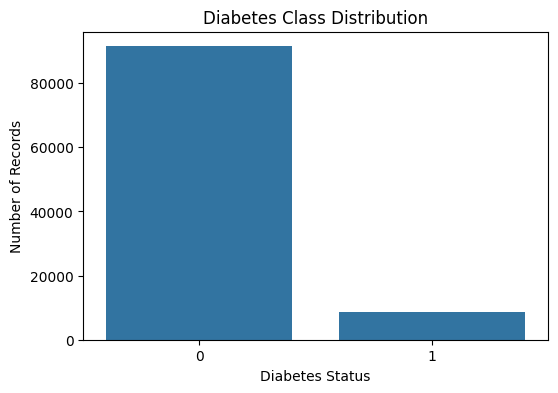

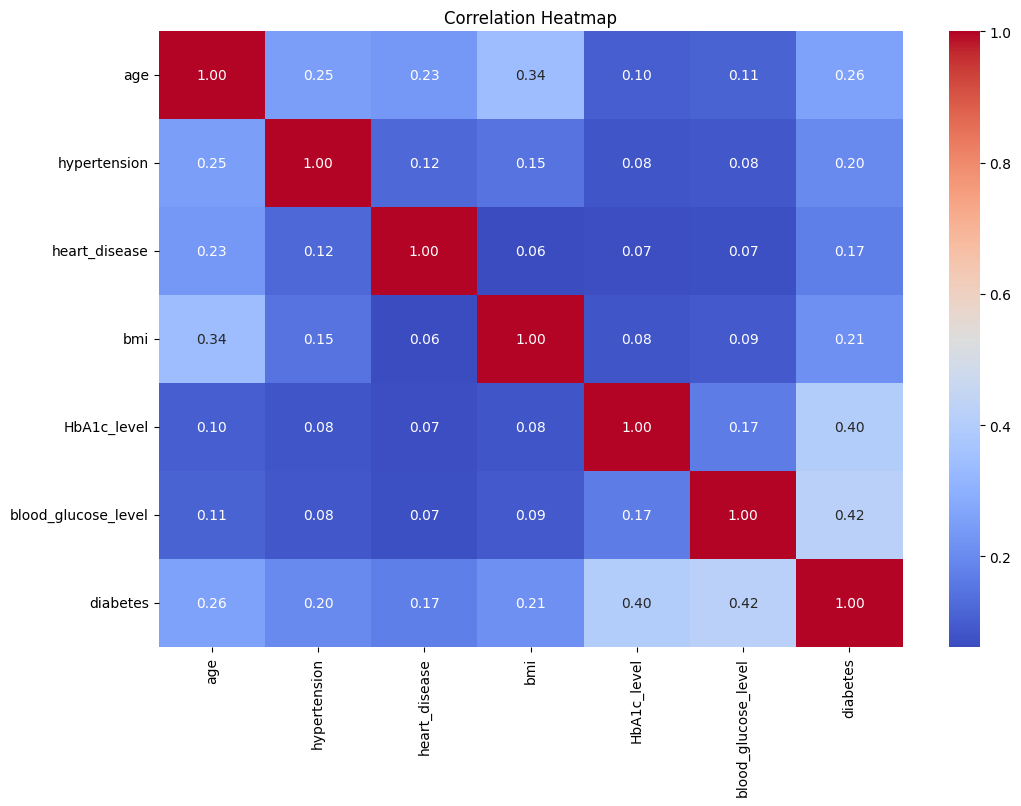

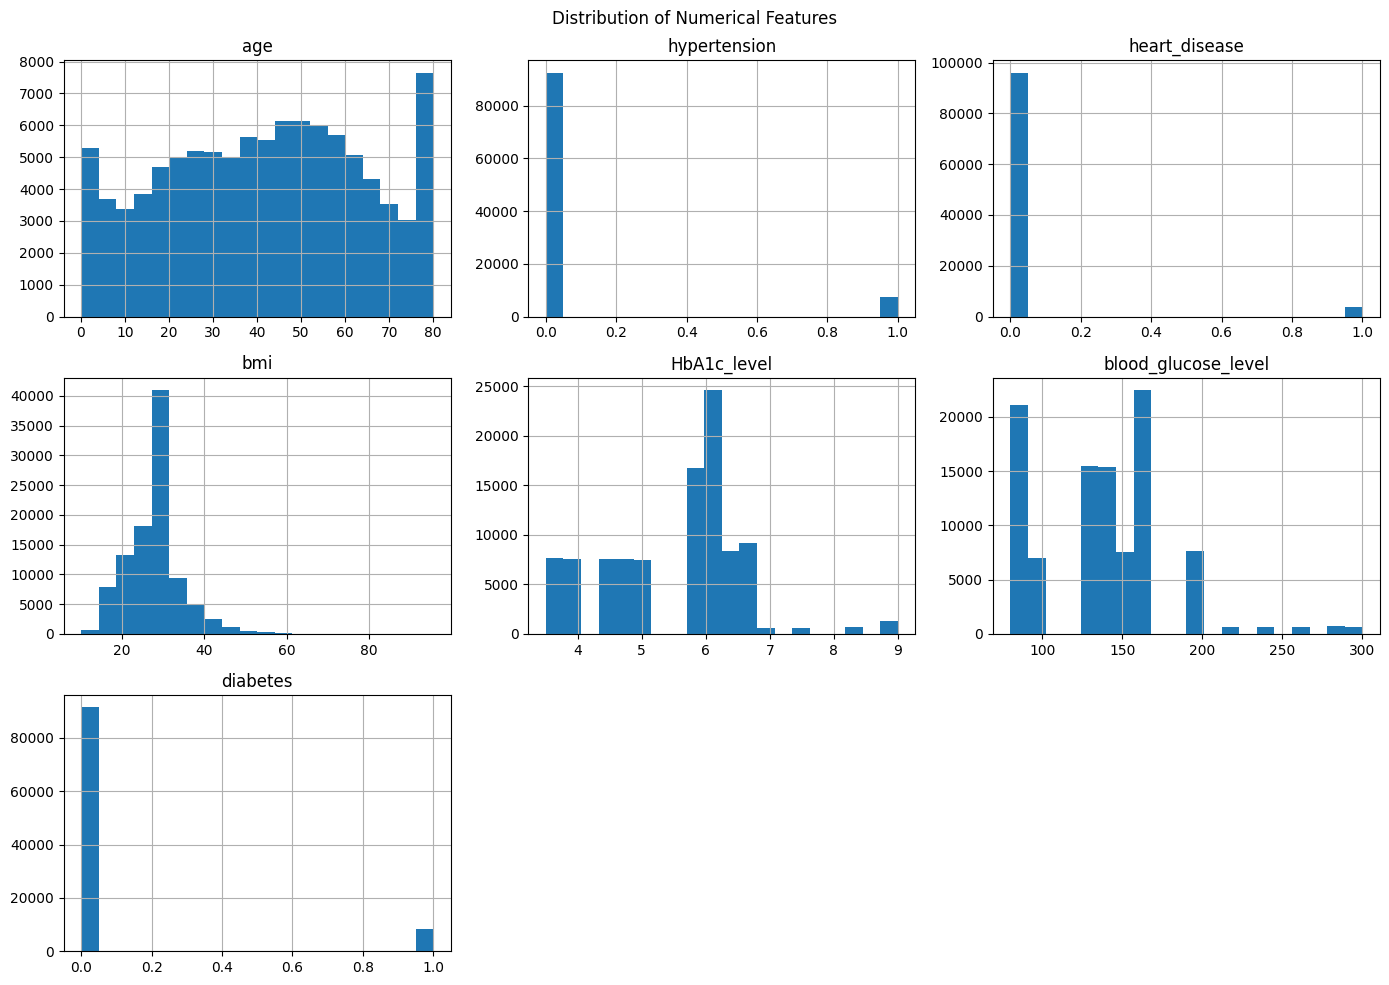

In [24]:
# SECTION 5: DATA VISUALIZATION
# Visualizing the dataset to understand feature distributions
# and the distribution of diabetes and non-diabetes cases.

# Display target distribution if the target column is named diabetes
if 'diabetes' in df.columns:
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x='diabetes')
    plt.title("Diabetes Class Distribution")
    plt.xlabel("Diabetes Status")
    plt.ylabel("Number of Records")
    plt.show()

# Display correlation heatmap for numerical columns
plt.figure(figsize=(12, 8))

numeric_df = df.select_dtypes(include=np.number)

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

# Display numerical feature distributions
numeric_df.hist(figsize=(14, 10), bins=20)
plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

In [25]:
# SECTION 6: DATA PREPROCESSING
# Identifying the target variable, handling missing values,
# encoding categorical features, and preparing input features.

# Automatically identify the target column
possible_targets = [
    'diabetes', 'Diabetes', 'Outcome',
    'outcome', 'target', 'Target', 'class'
]

target_column = next(
    (col for col in possible_targets if col in df.columns),
    None
)

if target_column is None:
    raise ValueError(
        "Target column not found. Please check your dataset columns."
    )

print("Target Column:", target_column)

# Remove duplicate records
df = df.drop_duplicates()

# Remove records with missing target values
df = df.dropna(subset=[target_column])

# Separate input features and target variable
X = df.drop(columns=[target_column])
y = df[target_column]

# Remove identifier columns if present
id_columns = [
    col for col in X.columns
    if col.lower() in ['id', 'patient_id', 'patientid']
]

X = X.drop(columns=id_columns)

# Convert target labels into numeric values if necessary
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y.astype(str))

# Check target classes
print("\nTarget Classes:", label_encoder.classes_)
print("Number of Classes:", len(np.unique(y)))

# This implementation is designed for binary diabetes classification
if len(np.unique(y)) != 2:
    raise ValueError("This notebook currently supports binary classification only.")

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("\nNumerical Features:", numeric_features)
print("Categorical Features:", categorical_features)

# Create preprocessing pipelines
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

# Apply transformations to the appropriate columns
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='drop'
)

print("\nPreprocessing Configuration Created Successfully!")

Target Column: diabetes

Target Classes: ['0' '1']
Number of Classes: 2

Numerical Features: ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level']
Categorical Features: ['gender', 'smoking_history']

Preprocessing Configuration Created Successfully!


In [26]:
# SECTION 7: TRAIN-TEST SPLITTING
# Splitting the dataset into 80% training data and 20% testing data.
# Stratification maintains the class distribution in both sets.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Fit preprocessing only on training data to prevent data leakage
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

# Convert processed data into NumPy arrays
X_train = np.asarray(X_train, dtype=np.float32)
X_test = np.asarray(X_test, dtype=np.float32)

y_train = np.asarray(y_train, dtype=np.int32)
y_test = np.asarray(y_test, dtype=np.int32)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nData Splitting Completed Successfully!")

Training Data Shape: (76916, 15)
Testing Data Shape: (19230, 15)

Data Splitting Completed Successfully!


In [27]:
# SECTION 8: MODEL EVALUATION FUNCTION
# This function calculates accuracy, precision, recall,
# F1-score, ROC-AUC, and training time for each model.

results = []
model_predictions = {}
model_probabilities = {}
trained_models = {}

def evaluate_model(name, y_true, y_pred, y_prob, training_time):

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auc = roc_auc_score(y_true, y_prob)

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'ROC-AUC': auc,
        'Training Time (sec)': training_time
    })

    model_predictions[name] = y_pred
    model_probabilities[name] = y_prob

    print(f"\n{name} Results")
    print("-" * 40)
    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))
    print("ROC-AUC  :", round(auc, 4))
    print("Training Time:", round(training_time, 2), "seconds")

    print("\nClassification Report:")
    print(classification_report(
        y_true, y_pred,
        target_names=['No Diabetes', 'Diabetes'],
        zero_division=0
    ))

In [28]:
# SECTION 14: DEEP LEARNING DATA PREPARATION
# Calculate class weights to help neural networks handle
# imbalanced diabetes and non-diabetes classes.

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class Weights:", class_weights)

# Define early stopping to prevent unnecessary training
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Define a common function for compiling and training DL models
def train_dl_model(model, name):

    start_time = time.time()

    model.fit(
        X_train,
        y_train,
        epochs=30,
        batch_size=128,
        validation_split=0.20,
        callbacks=[early_stopping],
        class_weight=class_weights,
        verbose=1
    )

    training_time = time.time() - start_time

    y_prob = model.predict(X_test, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    trained_models[name] = model

    evaluate_model(
        name,
        y_test,
        y_pred,
        y_prob,
        training_time
    )

    return model

Class Weights: {np.int32(0): np.float64(0.5483815770711535), np.int32(1): np.float64(5.667256115531978)}


In [29]:
# SECTION 15: DEEP LEARNING MODEL 1 - ARTIFICIAL NEURAL NETWORK
# ANN contains input, hidden, and output layers.
# It learns relationships between patient features and diabetes outcomes.

ann_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

ann_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

train_dl_model(ann_model, 'ANN')

Epoch 1/30
481/481 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8591 - loss: 0.2841 - val_accuracy: 0.8847 - val_loss: 0.2385
Epoch 2/30
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8852 - loss: 0.2334 - val_accuracy: 0.8892 - val_loss: 0.2233
Epoch 3/30
481/481 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8854 - loss: 0.2190 - val_accuracy: 0.8912 - val_loss: 0.2171
Epoch 4/30
481/481 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8873 - loss: 0.2077 - val_accuracy: 0.9001 - val_loss: 0.1950
Epoch 5/30
481/481 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8907 - loss: 0.2011 - val_accuracy: 0.8898 - val_loss: 0.2117
Epoch 6/30
481/481 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8899 - loss: 0.1970 - val_accuracy: 0.8915 - val_loss: 0.1957
Epoch 7/30
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8938 - loss: 0.1926 - val_accuracy: 0.8955 - val_loss: 0.1927
Epoch 8/30
481/481 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8937 - loss: 0.1907 - val_accuracy: 0.

<Sequential name=sequential, built=True>

In [30]:
# SECTION 16: DEEP LEARNING MODEL 2 - DEEP NEURAL NETWORK
# DNN uses multiple hidden layers to learn more complex
# patterns from the diabetes prediction dataset.

dnn_model = Sequential([
    Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.3),

    Dense(64, activation='relu'),
    Dropout(0.2),

    Dense(32, activation='relu'),

    Dense(1, activation='sigmoid')
])

dnn_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

train_dl_model(dnn_model, 'DNN')

Epoch 1/30
481/481 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.8420 - loss: 0.2876 - val_accuracy: 0.8823 - val_loss: 0.2333
Epoch 2/30
481/481 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8793 - loss: 0.2351 - val_accuracy: 0.8905 - val_loss: 0.2066
Epoch 3/30
481/481 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8844 - loss: 0.2136 - val_accuracy: 0.9009 - val_loss: 0.1777
Epoch 4/30
481/481 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8880 - loss: 0.2033 - val_accuracy: 0.8890 - val_loss: 0.1938
Epoch 5/30
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8909 - loss: 0.1987 - val_accuracy: 0.8937 - val_loss: 0.1850

DNN Results
----------------------------------------
Accuracy : 0.8764
Precision: 0.4087
Recall   : 0.898
F1 Score : 0.5618
ROC-AUC  : 0.9625
Training Time: 14.79 seconds

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.99      0.87      0.93     17534
    Diabetes       0.41      0.90      0.56      1696



<Sequential name=sequential_1, built=True>

In [31]:
# SECTION 17: DEEP LEARNING MODEL 3 - CONVOLUTIONAL NEURAL NETWORK
# CNN uses one-dimensional convolution to learn local patterns
# among the input features. Here, tabular features are reshaped
# into a one-dimensional feature sequence.

cnn_model = Sequential([
    tf.keras.Input(shape=(X_train.shape[1], 1)),

    Conv1D(
        filters=32,
        kernel_size=3,
        activation='relu',
        padding='same'
    ),

    MaxPooling1D(pool_size=2),

    Flatten(),

    Dense(64, activation='relu'),
    Dropout(0.3),

    Dense(1, activation='sigmoid')
])

cnn_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

X_train_cnn = X_train.reshape(
    X_train.shape[0], X_train.shape[1], 1
)

X_test_cnn = X_test.reshape(
    X_test.shape[0], X_test.shape[1], 1
)

# Temporarily use CNN-shaped input during training
X_train_original = X_train
X_test_original = X_test

X_train = X_train_cnn
X_test = X_test_cnn

train_dl_model(cnn_model, 'CNN')

# Restore original two-dimensional data for remaining models
X_train = X_train_original
X_test = X_test_original

Epoch 1/30
481/481 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.8592 - loss: 0.2737 - val_accuracy: 0.8868 - val_loss: 0.2256
Epoch 2/30
481/481 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8830 - loss: 0.2243 - val_accuracy: 0.8950 - val_loss: 0.2076
Epoch 3/30
481/481 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8866 - loss: 0.2131 - val_accuracy: 0.8697 - val_loss: 0.2422
Epoch 4/30
481/481 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8878 - loss: 0.2075 - val_accuracy: 0.9051 - val_loss: 0.1870
Epoch 5/30
481/481 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8908 - loss: 0.2020 - val_accuracy: 0.8847 - val_loss: 0.2052

CNN Results
----------------------------------------
Accuracy : 0.879
Precision: 0.4146
Recall   : 0.9015
F1 Score : 0.568
ROC-AUC  : 0.965
Training Time: 17.8 seconds

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.99      0.88      0.93     17534
    Diabetes       0.41      0.90      0.57      1696

 

In [32]:
# SECTION 18: DEEP LEARNING MODEL 4 - LONG SHORT-TERM MEMORY
# LSTM is a recurrent neural network designed to learn
# sequential dependencies. Here, tabular features are treated
# as an experimental feature sequence, not actual time-series data.

lstm_model = Sequential([
    tf.keras.Input(shape=(X_train.shape[1], 1)),

    LSTM(64, return_sequences=True),

    LSTM(32),

    Dense(32, activation='relu'),

    Dropout(0.3),

    Dense(1, activation='sigmoid')
])

lstm_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

X_train_lstm = X_train.reshape(
    X_train.shape[0], X_train.shape[1], 1
)

X_test_lstm = X_test.reshape(
    X_test.shape[0], X_test.shape[1], 1
)

X_train_original = X_train
X_test_original = X_test

X_train = X_train_lstm
X_test = X_test_lstm

train_dl_model(lstm_model, 'LSTM')

X_train = X_train_original
X_test = X_test_original


Epoch 1/30
481/481 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.8264 - loss: 0.3388 - val_accuracy: 0.9067 - val_loss: 0.2337
Epoch 2/30
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8699 - loss: 0.2959 - val_accuracy: 0.8914 - val_loss: 0.2616
Epoch 3/30
481/481 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.8652 - loss: 0.2870 - val_accuracy: 0.8842 - val_loss: 0.2287
Epoch 4/30
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8676 - loss: 0.2785 - val_accuracy: 0.8639 - val_loss: 0.2690
Epoch 5/30
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8647 - loss: 0.2712 - val_accuracy: 0.8649 - val_loss: 0.2799

LSTM Results
----------------------------------------
Accuracy : 0.9027
Precision: 0.4702
Recall   : 0.8137
F1 Score : 0.596
ROC-AUC  : 0.948
Training Time: 27.98 seconds

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.98      0.91      0.94     17534
    Diabetes       0.47      0.81      0.60      1696

In [33]:
# SECTION 19: DEEP LEARNING MODEL 5 - GATED RECURRENT UNIT
# GRU is a recurrent neural network that uses gating mechanisms
# to learn dependencies with fewer gates than LSTM.

gru_model = Sequential([
    tf.keras.Input(shape=(X_train.shape[1], 1)),

    GRU(64, return_sequences=True),

    GRU(32),

    Dense(32, activation='relu'),

    Dropout(0.3),

    Dense(1, activation='sigmoid')
])

gru_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

X_train_gru = X_train.reshape(
    X_train.shape[0], X_train.shape[1], 1
)

X_test_gru = X_test.reshape(
    X_test.shape[0], X_test.shape[1], 1
)

X_train_original = X_train
X_test_original = X_test

X_train = X_train_gru
X_test = X_test_gru

train_dl_model(gru_model, 'GRU')

X_train = X_train_original
X_test = X_test_original

Epoch 1/30
481/481 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8414 - loss: 0.3382 - val_accuracy: 0.8621 - val_loss: 0.2854
Epoch 2/30
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8719 - loss: 0.2862 - val_accuracy: 0.8817 - val_loss: 0.2739
Epoch 3/30
481/481 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8782 - loss: 0.2742 - val_accuracy: 0.8773 - val_loss: 0.2650
Epoch 4/30
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8746 - loss: 0.2616 - val_accuracy: 0.8641 - val_loss: 0.2686
Epoch 5/30
481/481 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8712 - loss: 0.2518 - val_accuracy: 0.8896 - val_loss: 0.2189

GRU Results
----------------------------------------
Accuracy : 0.8556
Precision: 0.3682
Recall   : 0.8892
F1 Score : 0.5207
ROC-AUC  : 0.9498
Training Time: 23.66 seconds

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.99      0.85      0.92     17534
    Diabetes       0.37      0.89      0.52      1696

In [34]:
# SECTION 20: COMPARISON OF ALL MACHINE LEARNING
# AND DEEP LEARNING MODELS
# Creating a comparison table using all evaluation metrics.

results_df = pd.DataFrame(results)

# Sort models according to accuracy
results_df = results_df.sort_values(
    by='Accuracy',
    ascending=False
).reset_index(drop=True)

print("FINAL MODEL PERFORMANCE COMPARISON")

display(
    results_df.style.format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1 Score': '{:.4f}',
        'ROC-AUC': '{:.4f}',
        'Training Time (sec)': '{:.2f}'
    }).highlight_max(
        subset=['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC'],
        color='lightgreen'
    )
)

# Identify the best model based on accuracy
best_model = results_df.iloc[0]

print("\nBEST PERFORMING MODEL")
print("Model Name:", best_model['Model'])
print("Accuracy:", round(best_model['Accuracy'] * 100, 2), "%")

FINAL MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (sec)
0,ANN,0.9049,0.4789,0.8850,0.6215,0.9738,40.78
1,LSTM,0.9027,0.4702,0.8137,0.5960,0.9480,27.98
2,CNN,0.8790,0.4146,0.9015,0.5680,0.9650,17.80
3,DNN,0.8764,0.4087,0.8980,0.5618,0.9625,14.79
4,GRU,0.8556,0.3682,0.8892,0.5207,0.9498,23.66



BEST PERFORMING MODEL
Model Name: ANN
Accuracy: 90.49 %


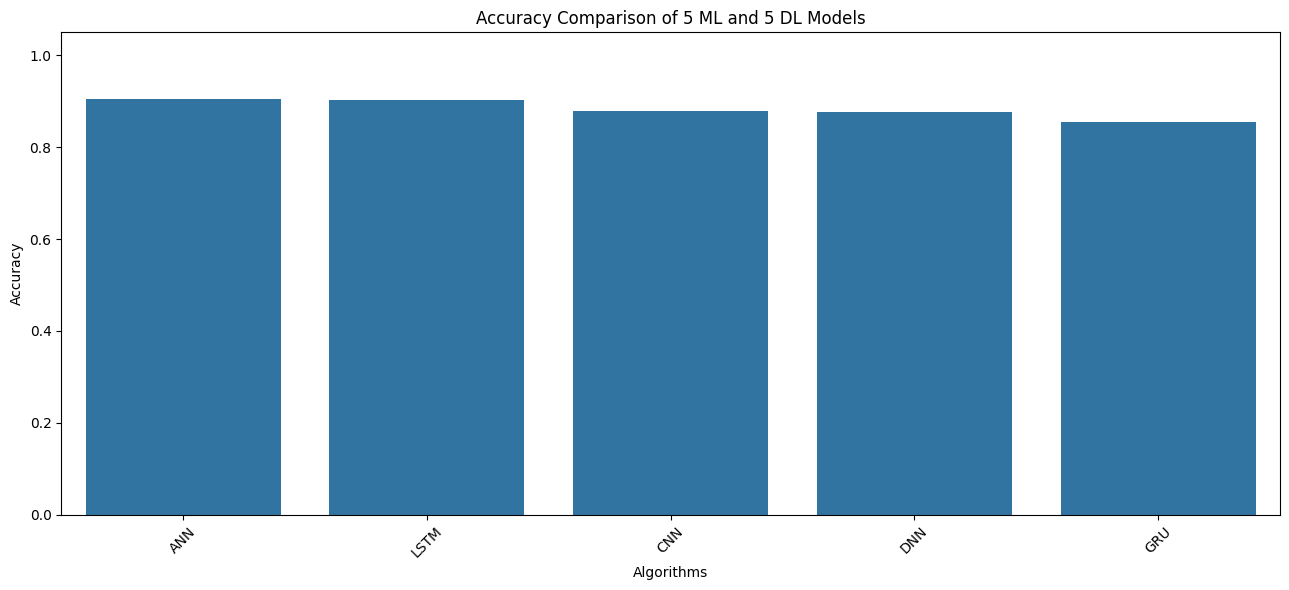

In [35]:
# SECTION 21: ACCURACY COMPARISON GRAPH
# Comparing the accuracy of all 10 trained models
# using a bar chart.

plt.figure(figsize=(13, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy'
)

plt.title("Accuracy Comparison of 5 ML and 5 DL Models")
plt.xlabel("Algorithms")
plt.ylabel("Accuracy")
plt.xticks(rotation=45)
plt.ylim(0, 1.05)

plt.tight_layout()
plt.show()

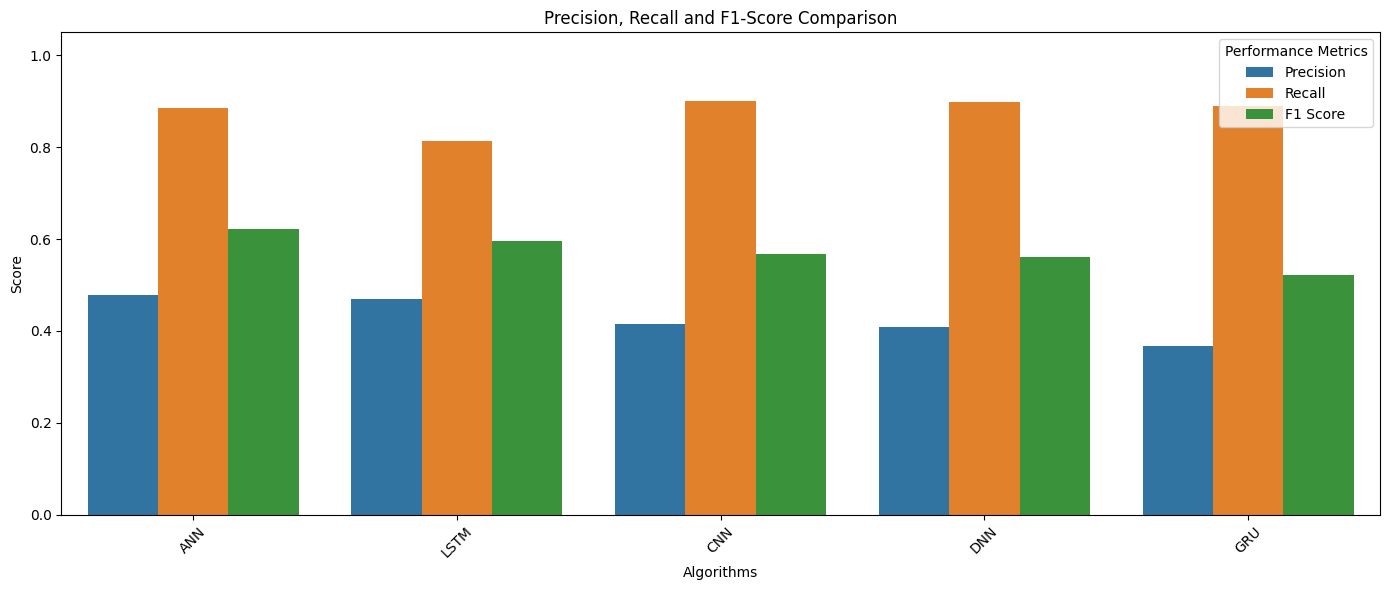

In [36]:
# SECTION 22: PERFORMANCE METRICS COMPARISON
# Comparing Precision, Recall, and F1-score for all models.

metrics_df = results_df.melt(
    id_vars='Model',
    value_vars=['Precision', 'Recall', 'F1 Score'],
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(14, 6))

sns.barplot(
    data=metrics_df,
    x='Model',
    y='Score',
    hue='Metric'
)

plt.title("Precision, Recall and F1-Score Comparison")
plt.xlabel("Algorithms")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.ylim(0, 1.05)

plt.legend(title="Performance Metrics")
plt.tight_layout()
plt.show()

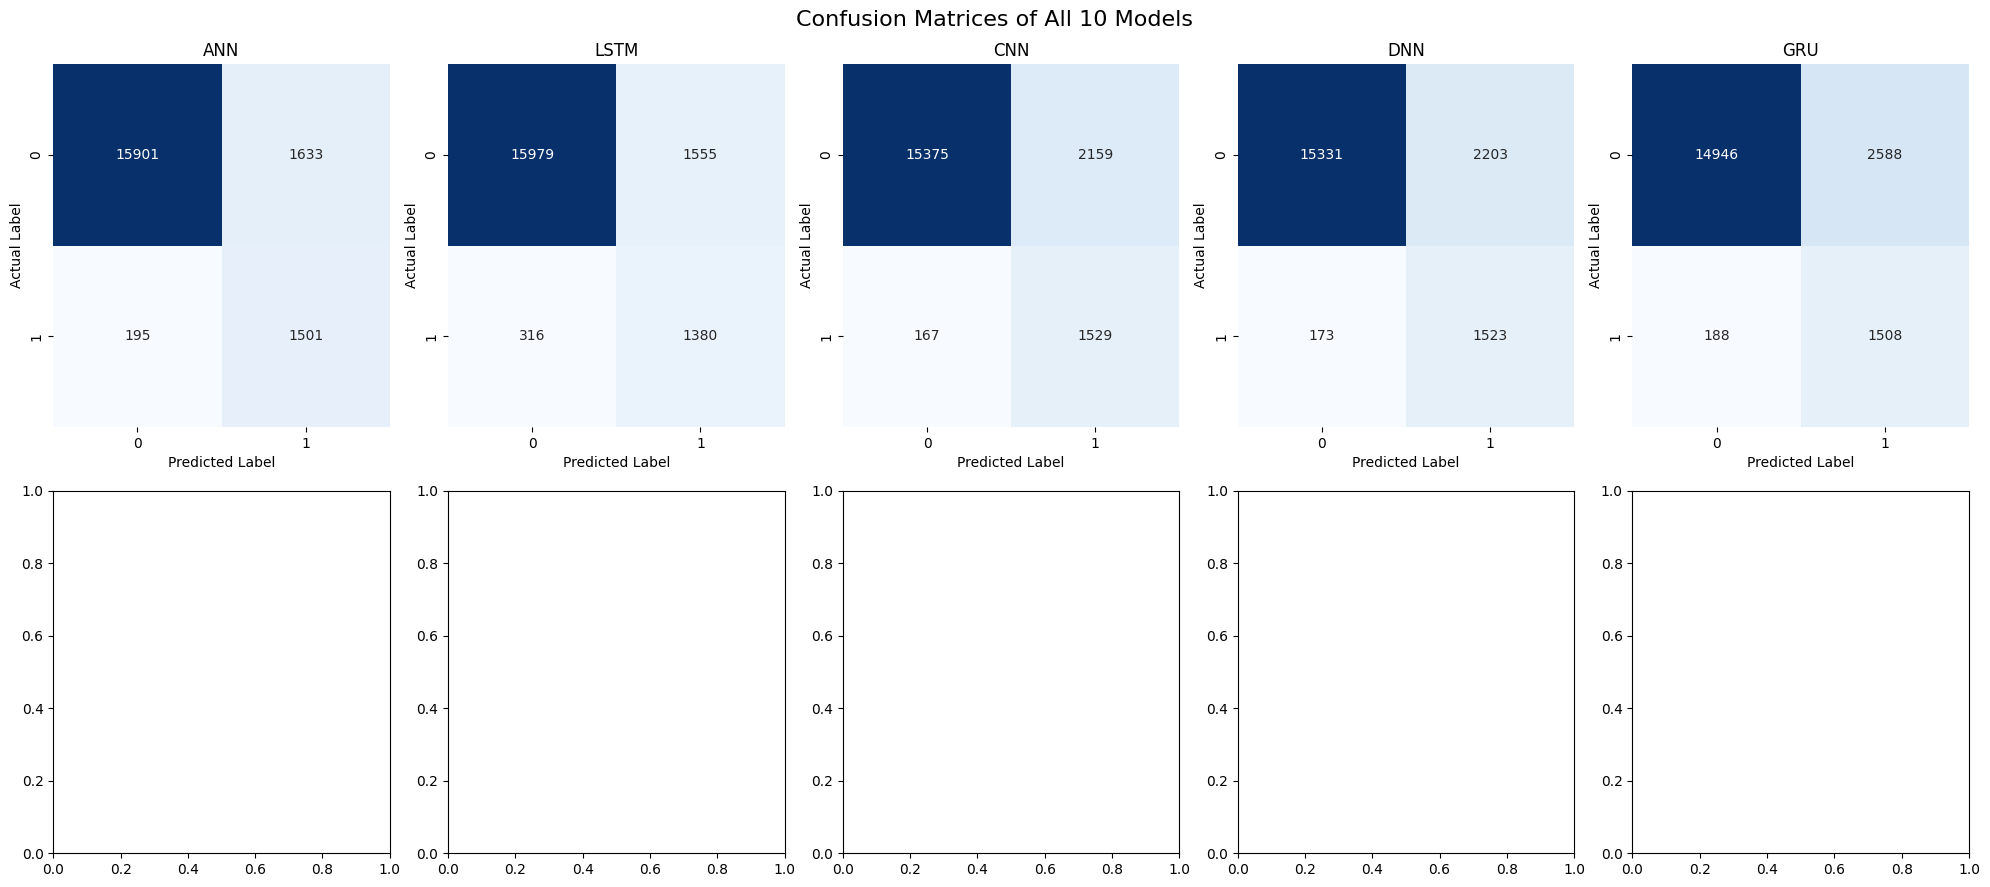

In [37]:
# SECTION 23: CONFUSION MATRIX COMPARISON
# A confusion matrix displays correct and incorrect predictions
# for diabetes and non-diabetes classes.

fig, axes = plt.subplots(2, 5, figsize=(20, 9))

for ax, model_name in zip(axes.flatten(), results_df['Model']):

    cm = confusion_matrix(
        y_test,
        model_predictions[model_name]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax,
        cbar=False
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.suptitle(
    "Confusion Matrices of All 10 Models",
    fontsize=16
)

plt.tight_layout()
plt.show()

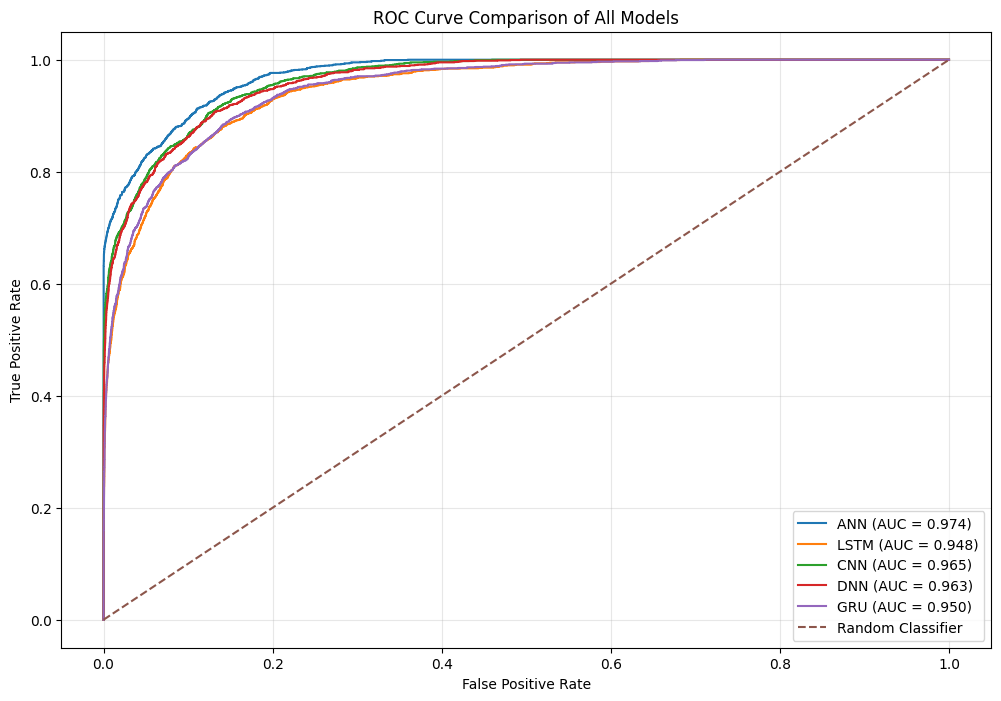

In [38]:
# SECTION 24: ROC CURVE COMPARISON
# ROC curves compare the ability of different models
# to distinguish between diabetes and non-diabetes classes.

plt.figure(figsize=(12, 8))

for model_name in results_df['Model']:

    fpr, tpr, thresholds = roc_curve(
        y_test,
        model_probabilities[model_name]
    )

    auc = roc_auc_score(
        y_test,
        model_probabilities[model_name]
    )

    plt.plot(
        fpr,
        tpr,
        label=f'{model_name} (AUC = {auc:.3f})'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.title("ROC Curve Comparison of All Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc='lower right')
plt.grid(alpha=0.3)

plt.show()

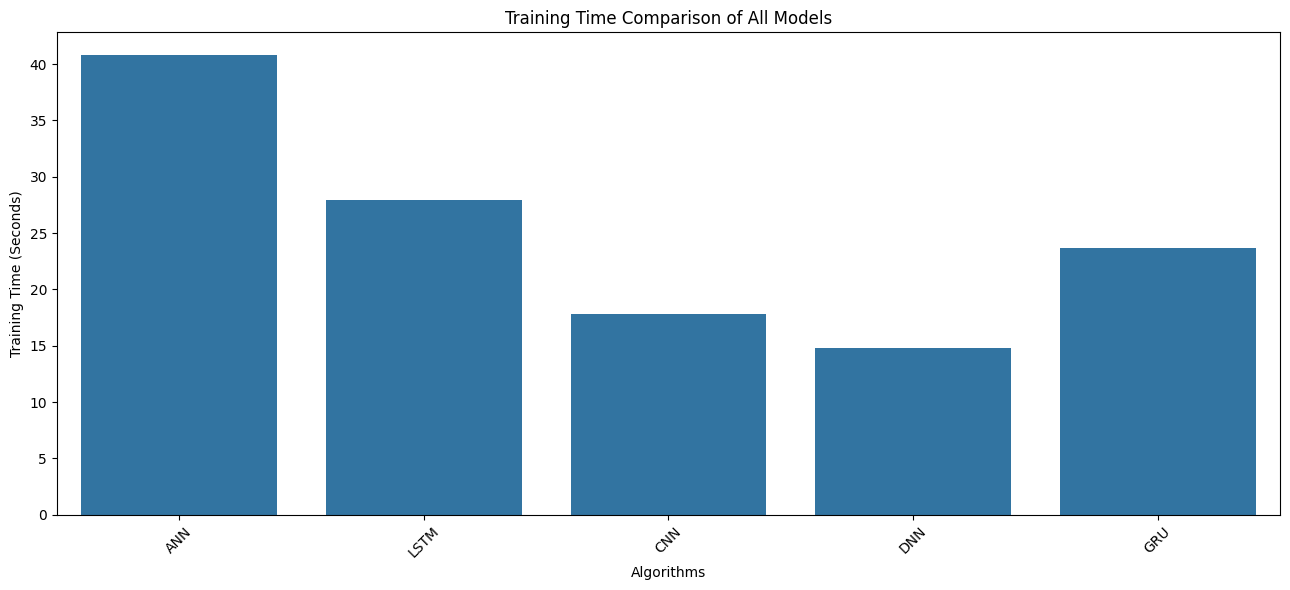

In [39]:
# SECTION 25: TRAINING TIME COMPARISON
# Comparing the time required by each algorithm to train
# on the diabetes prediction dataset.

plt.figure(figsize=(13, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='Training Time (sec)'
)

plt.title("Training Time Comparison of All Models")
plt.xlabel("Algorithms")
plt.ylabel("Training Time (Seconds)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [40]:
# ============================================================
# SECTION: SAVING ALL DEEP LEARNING MODEL RESULTS
# Models: ANN, DNN, CNN, LSTM, GRU
# Destination: My Drive/3 rd sem Practical/Result
# Existing ML results will NOT be modified.
# ============================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

# 1. SET RESULT FOLDER PATH

output_folder = '/content/drive/MyDrive/MCA3/DSP_Project/results/DL results'

os.makedirs(output_folder, exist_ok=True)

# 2. SELECT ONLY DEEP LEARNING MODELS

dl_models = ['ANN', 'DNN', 'CNN', 'LSTM', 'GRU']

dl_results = [
    r for r in results
    if r['Model'] in dl_models
]

dl_results_df = pd.DataFrame(dl_results)

dl_results_df = dl_results_df.sort_values(
    by='Accuracy',
    ascending=False
).reset_index(drop=True)

# 3. SAVE DEEP LEARNING PERFORMANCE METRICS

dl_results_df.to_csv(
    output_folder + '/DL_Performance_Metrics.csv',
    index=False
)

# 4. SAVE INDIVIDUAL CONFUSION MATRICES

for model_name in dl_models:

    cm = confusion_matrix(
        y_test,
        model_predictions[model_name]
    )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Greens',
        xticklabels=['No Diabetes', 'Diabetes'],
        yticklabels=['No Diabetes', 'Diabetes']
    )

    plt.title(model_name + ' Confusion Matrix')
    plt.xlabel('Predicted Label')
    plt.ylabel('Actual Label')

    plt.tight_layout()

    plt.savefig(
        output_folder + '/' + model_name + '_Confusion_Matrix.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.close()

# 5. SAVE COMBINED CONFUSION MATRIX

fig, axes = plt.subplots(1, 5, figsize=(22, 5))

for ax, model_name in zip(axes, dl_models):

    cm = confusion_matrix(
        y_test,
        model_predictions[model_name]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Greens',
        xticklabels=['No', 'Yes'],
        yticklabels=['No', 'Yes'],
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.suptitle('Deep Learning - Confusion Matrix Comparison')
plt.tight_layout()

plt.savefig(
    output_folder + '/DL_All_Confusion_Matrices.png',
    dpi=300,
    bbox_inches='tight'
)

plt.close()

# 6. SAVE ACCURACY COMPARISON GRAPH

plt.figure(figsize=(10, 6))

sns.barplot(
    data=dl_results_df,
    x='Model',
    y='Accuracy',
    hue='Model',
    legend=False,
    palette='Greens_d'
)

plt.title('Accuracy Comparison - Deep Learning Models')
plt.xlabel('Deep Learning Algorithms')
plt.ylabel('Accuracy')
plt.ylim(0, 1.05)
plt.tight_layout()

plt.savefig(
    output_folder + '/DL_Accuracy_Comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.close()

# 7. SAVE PRECISION, RECALL AND F1 SCORE GRAPH

metrics_df = dl_results_df.melt(
    id_vars='Model',
    value_vars=['Precision', 'Recall', 'F1 Score'],
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=metrics_df,
    x='Model',
    y='Score',
    hue='Metric'
)

plt.title('DL Performance Metrics Comparison')
plt.ylim(0, 1.05)
plt.tight_layout()

plt.savefig(
    output_folder + '/DL_Metrics_Comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.close()

# 8. SAVE ROC CURVE COMPARISON

plt.figure(figsize=(9, 7))

for model_name in dl_models:

    y_prob = model_probabilities[model_name]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    auc = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f'{model_name} (AUC={auc:.3f})'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.title('ROC Curve - Deep Learning Models')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    output_folder + '/DL_ROC_Curve.png',
    dpi=300,
    bbox_inches='tight'
)

plt.close()

# 9. SAVE TRAINING TIME COMPARISON

plt.figure(figsize=(10, 6))

sns.barplot(
    data=dl_results_df,
    x='Model',
    y='Training Time (sec)',
    hue='Model',
    legend=False
)

plt.title('Training Time - Deep Learning Models')
plt.xlabel('Deep Learning Models')
plt.ylabel('Time (Seconds)')
plt.tight_layout()

plt.savefig(
    output_folder + '/DL_Training_Time.png',
    dpi=300,
    bbox_inches='tight'
)

plt.close()

# 10. SAVE CLASSIFICATION REPORTS

with open(
    output_folder + '/DL_Classification_Reports.txt',
    'w'
) as file:

    for model_name in dl_models:

        report = classification_report(
            y_test,
            model_predictions[model_name],
            target_names=['No Diabetes', 'Diabetes'],
            zero_division=0
        )

        file.write('\n' + '=' * 60 + '\n')
        file.write(model_name + '\n')
        file.write('=' * 60 + '\n')
        file.write(report + '\n')

# 11. SAVE ACTUAL VS PREDICTED VALUES

prediction_df = pd.DataFrame({
    'Actual': y_test
})

for model_name in dl_models:

    prediction_df[model_name] = model_predictions[model_name]

prediction_df.to_csv(
    output_folder + '/DL_Actual_vs_Predicted.csv',
    index=False
)

# 12. SAVE COMPLETE DEEP LEARNING RESULTS IN EXCEL

excel_path = output_folder + '/Complete_DL_Results.xlsx'

with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:

    dl_results_df.to_excel(
        writer,
        sheet_name='Performance Metrics',
        index=False
    )

    prediction_df.to_excel(
        writer,
        sheet_name='Predictions',
        index=False
    )

    for model_name in dl_models:

        cm = confusion_matrix(
            y_test,
            model_predictions[model_name]
        )

        cm_df = pd.DataFrame(
            cm,
            index=['Actual No Diabetes', 'Actual Diabetes'],
            columns=['Predicted No Diabetes', 'Predicted Diabetes']
        )

        cm_df.to_excel(
            writer,
            sheet_name=model_name
        )

# 13. DISPLAY BEST DEEP LEARNING MODEL

best_model = dl_results_df.iloc[0]

print("\n" + "=" * 60)
print("DEEP LEARNING RESULTS SAVED SUCCESSFULLY!")
print("=" * 60)

print("\nBest Deep Learning Model:", best_model['Model'])
print("Best Accuracy:", round(best_model['Accuracy'] * 100, 2), "%")

print("\nSaved Location:")
print(output_folder)

# 14. DISPLAY ALL SAVED DL FILES

print("\nDeep Learning Result Files:")

dl_files = [
    'DL_Performance_Metrics.csv',
    'DL_All_Confusion_Matrices.png',
    'DL_Accuracy_Comparison.png',
    'DL_Metrics_Comparison.png',
    'DL_ROC_Curve.png',
    'DL_Training_Time.png',
    'DL_Classification_Reports.txt',
    'DL_Actual_vs_Predicted.csv',
    'Complete_DL_Results.xlsx'
]

for filename in dl_files:
    print("✔", filename)

print("\n" + "=" * 60)

display(dl_results_df)


DEEP LEARNING RESULTS SAVED SUCCESSFULLY!

Best Deep Learning Model: ANN
Best Accuracy: 90.49 %

Saved Location:
/content/drive/MyDrive/MCA3/DSP_Project/results/DL results

Deep Learning Result Files:
✔ DL_Performance_Metrics.csv
✔ DL_All_Confusion_Matrices.png
✔ DL_Accuracy_Comparison.png
✔ DL_Metrics_Comparison.png
✔ DL_ROC_Curve.png
✔ DL_Training_Time.png
✔ DL_Classification_Reports.txt
✔ DL_Actual_vs_Predicted.csv
✔ Complete_DL_Results.xlsx



,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (sec)
0,ANN,0.904940,0.478941,0.885024,0.621532,0.973783,40.784482
1,LSTM,0.902704,0.470187,0.813679,0.595984,0.948040,27.978012
2,CNN,0.879043,0.414588,0.901533,0.567979,0.965022,17.800053
3,DNN,0.876443,0.408749,0.897995,0.561785,0.962542,14.793932
4,GRU,0.855642,0.368164,0.889151,0.520718,0.949821,23.662656


In [41]:
#saving best models models

import joblib
import os

model_save_dir = '/content/drive/MyDrive/MCA3/DSP_Project/Models'
os.makedirs(model_save_dir, exist_ok=True)

# 1. Direct rf_model save karein
ml_model_path = os.path.join(model_save_dir, 'Best_Random_Forest_Model.pkl')
joblib.dump(rf_model, ml_model_path)
print(f"✔ Best ML Model (Random Forest) saved to: {ml_model_path}")

# 2. Direct ann_model save karein
dl_model_path = os.path.join(model_save_dir, 'Best_ANN_Model.keras')
ann_model.save(dl_model_path)
print(f"✔ Best DL Model (ANN) saved to: {dl_model_path}")

✔ Best ML Model (Random Forest) saved to: /content/drive/MyDrive/MCA3/DSP_Project/Models/Best_Random_Forest_Model.pkl
✔ Best DL Model (ANN) saved to: /content/drive/MyDrive/MCA3/DSP_Project/Models/Best_ANN_Model.keras


In [42]:
import joblib
joblib.dump(preprocessor, '/content/drive/MyDrive/MCA3/DSP_Project/Models/preprocessor.pkl')
print("Preprocessor saved successfully!")

Preprocessor saved successfully!
